# BOLOS 1.0.0 vs BOLSIG+: numerical comparison

This notebook computes fresh BOLOS results and compares them with the **included
BOLSIG+ 07/2024 export**, rather than with historical BOLOS validation JSON.
It compares the stored distribution (eV$^{-3/2}$), selected unweighted reaction
rate coefficients (m$^3$/s), reduced mobility $\mu N$, reduced diffusion $DN$,
mean energy, and the derived characteristic energy $DN/(\mu N)$ (eV).

**Run all cells** using the environment containing this repository's BOLOS,
NumPy, SciPy, Matplotlib, pandas, IPython, and Jupyter kernel. Start in the
repository root or one of its subdirectories. For example, install
`python -m pip install -e ".[validation]" pandas` and use that Python kernel.

The reference is `Phelps/N2-O2_80-20_2000Td.dat`; despite its name it contains
a sweep of reduced fields. The input is `Phelps/Phelps_N2-O2_20261026.txt`.
No BOLSIG+ executable is launched. The export records N2:O2 = 80:20 at 300 K,
DC conditions, and 100 BOLSIG+ grid points. BOLOS uses its own discretization.
This is a reproducible solver comparison, not a claim of identical algorithms
or a universal accuracy certificate. The export does not contain a checksum
of its original input; we verify available process metadata and record the
checksums of the supplied files, but cannot prove historical input identity.

**Numerical revision (2026-11-05):** this saved execution uses the corrected logarithmic-slope handoff in `Process.scatterings()` (`gj = -g[self.j]`). The integral helper retains its `exp(g * (E_ref - E))` contract. Previous output values have been recomputed; see [the sign audit](docs/COLLISION_SIGN_VALIDATION.md) for the derivation and legacy comparison.

In [1]:
from pathlib import Path
from io import StringIO
from contextlib import contextmanager
from importlib.metadata import version
import hashlib
import json
import logging
import platform
import re
import sys
import warnings

import numpy as np
import pandas as pd
import scipy
import scipy.constants as constants
from scipy.integrate import trapezoid
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.grid": True})

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "bolos/solver.py").is_file() and (p / "Phelps").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the Py3bolos-master root or a subdirectory.")
sys.path.insert(0, str(ROOT))
from bolos import grid, parser, solver
assert Path(solver.__file__).resolve().parent == (ROOT / "bolos").resolve(), (
    "Another BOLOS is already imported. Restart the kernel and Run All."
)

CS_PATH = ROOT / "Phelps/Phelps_N2-O2_20261026.txt"
REF_PATH = ROOT / "Phelps/N2-O2_80-20_2000Td.dat"
OUT = ROOT / "validation/bolsig_comparison_corrected"
OUT.mkdir(parents=True, exist_ok=True)
REQUESTED_FIELDS = [1, 3, 10, 30, 100, 300, 1000, 2000]
RTOL = 1e-7
FINAL_CELLS = 600
REFINED_CELLS = 1200
CORE_FRACTION = 1e-6
RATE_RELATIVE_FLOOR = 1e-25  # Avoid percentages for negligible reference rates.

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

environment = {
    "python": platform.python_version(), "numpy": np.__version__,
    "scipy": scipy.__version__, "matplotlib": version("matplotlib"),
    "pandas": pd.__version__,
    "cross_section_sha256": sha256(CS_PATH),
    "bolsig_export_sha256": sha256(REF_PATH),
    "source_sha256": {p.name: sha256(p) for p in sorted((ROOT / "bolos").glob("*.py"))},
}
display(pd.Series({k: v for k, v in environment.items() if k != "source_sha256"},
                  name="Environment and input provenance").to_frame())

,Environment and input provenance
python,3.14.3
numpy,2.5.4
scipy,1.18.1
matplotlib,3.11.2
pandas,3.1.0
cross_section_sha256,7e96a9137c3bca3ff64c10afee9077b6f3742f4823d3de...
bolsig_export_sha256,bb66e2d255da5ab70354c6ad803031a2601d2c3e39bfd8...


## 1. Parse and audit the reference

Each `R<number>` block contains settings, scalar transport results, a table
indexed by collision IDs `C1`–`C43`, and a 100-point EEDF table. We select the
nearest **actual exported field**, display it, and use exactly that field in
BOLOS. Reaction IDs follow input-file order; species, kind, and rounded
threshold metadata are cross-checked. Repeated thresholds cannot be uniquely
identified from the abbreviated export labels alone, so input order is retained.

In [2]:
FLOAT = r"[+-]?(?:\d+\.?\d*|\.\d+)(?:[EeDd][+-]?\d+)?"

def scalar(block, label):
    match = re.search(r"^" + re.escape(label) + r"\s+(" + FLOAT + r")\s*$", block, re.M)
    if match is None:
        raise ValueError(f"Missing reference field: {label}")
    return float(match.group(1).replace("D", "E"))

def parse_reference(path):
    text = path.read_text(encoding="utf-8-sig")
    header = text.splitlines()[0]
    runs = []
    for match in re.finditer(r"^R(\d+)\s*\r?$([\s\S]*?)(?=^R\d+\s*\r?$|\Z)", text, re.M):
        block = match.group(2)
        entries = {}
        for row in re.finditer(r"^C(\d+)\s+(.+?)\s+(" + FLOAT + r")\s*$", block, re.M):
            entries[int(row.group(1))] = {
                "label": row.group(2).strip(),
                "rate": float(row.group(3).replace("D", "E")),
            }
        after = block.split("Energy (eV) EEDF (eV-3/2) Anisotropy", 1)[1]
        samples = []
        for line in after.splitlines():
            values = line.split()
            if len(values) == 3 and all(re.fullmatch(FLOAT, x) for x in values):
                samples.append([float(x.replace("D", "E")) for x in values])
            elif samples:
                break
        eedf = np.asarray(samples)
        assert eedf.ndim == 2 and eedf.shape[1] == 3
        assert np.all(np.diff(eedf[:, 0]) > 0) and np.all(np.isfinite(eedf))
        runs.append({
            "run": int(match.group(1)), "field": scalar(block, "Electric field / N (Td)"),
            "temperature": scalar(block, "Gas temperature (K)"),
            "N2": scalar(block, "Mole fraction N2"), "O2": scalar(block, "Mole fraction O2"),
            "frequency": scalar(block, "Angular frequency / N (m3.rad/s)"),
            "sharing": scalar(block, "Energy sharing"), "growth": scalar(block, "Growth model"),
            "mean_energy_eV": scalar(block, "Mean energy (eV)"),
            "mobility_N": scalar(block, "Mobility *N (1/m/V/s)"),
            "diffusion_N": scalar(block, "Diffusion coefficient *N (1/m/s)"),
            "grid_points": scalar(block, "# of grid points"),
            "rates": entries, "eedf": eedf,
        })
    if not runs:
        raise ValueError("No BOLSIG+ runs found.")
    return header, runs

reference_header, reference_runs = parse_reference(REF_PATH)
with CS_PATH.open(encoding="utf-8") as stream:
    definitions = parser.parse(stream)

selected = []
for requested in REQUESTED_FIELDS:
    ref = min(reference_runs, key=lambda run: abs(np.log(run["field"] / requested)))
    assert abs(ref["field"] / requested - 1) < 0.05, "No sufficiently close reference case"
    assert ref["run"] not in [r["run"] for r in selected]
    assert np.isclose(ref["temperature"], 300) and np.isclose(ref["frequency"], 0)
    assert np.isclose(ref["N2"], .8) and np.isclose(ref["O2"], .2)
    assert ref["sharing"] == 1 and ref["growth"] == 1
    assert list(ref["rates"]) == list(range(1, len(definitions) + 1))
    for collision_id, definition in enumerate(definitions, 1):
        label = ref["rates"][collision_id]["label"]
        assert label.split()[0] == definition["target"]
        expected = "Effective" if definition["kind"] in {"MOMENTUM", "EFFECTIVE"} else definition["kind"].title()
        assert expected.lower() in label.lower(), (collision_id, label, definition["kind"])
        threshold = re.search(r"(" + FLOAT + r")\s+eV", label)
        if threshold:
            assert np.isclose(float(threshold.group(1)), definition["threshold"], atol=.011, rtol=0)
    selected.append(ref)

print(reference_header, "| exported runs:", len(reference_runs), "| processes:", len(definitions))
display(pd.DataFrame({
    "requested_Td": REQUESTED_FIELDS, "actual_Td": [r["field"] for r in selected],
    "run_ID": [r["run"] for r in selected], "gas_K": [r["temperature"] for r in selected],
    "BOLSIG_grid_points": [r["grid_points"] for r in selected],
}))

BOLSIG+ version: 07/2024 | exported runs: 999 | processes: 43


,requested_Td,actual_Td,run_ID,gas_K,BOLSIG_grid_points
0,1,1.00000,1,300.0,100.0
1,3,3.05519,33,300.0,100.0
2,10,10.00950,68,300.0,100.0
3,30,29.90110,121,300.0,100.0
4,100,99.91400,223,300.0,100.0
5,300,300.03800,387,300.0,100.0
6,1000,1001.37000,707,300.0,100.0
7,2000,2000.00000,999,300.0,100.0


## 2. Compute BOLOS distributions and check numerical sensitivity

For each case: converge on a 500-cell linear grid (0–100 eV), then on a
600-cell quadratic grid. The final upper energy is the larger of 20 times
the preliminary mean energy and 1.25 times the last exported EEDF energy.
Repeat at 1200 cells with the same cutoff, and extend the cutoff by 1.5 while
increasing cells proportionally. Resolution and cutoff checks are reported
separately. The 600-cell calculation is the primary comparison.

We retain solver logs and NumPy warnings rather than suppressing their meaning.
Tiny negative samples are counted and their weighted negative population is
reported. Log plots omit nonpositive values **only for display**; no distribution
is clipped or renormalized before rates, transport, or discrepancy calculations.

In [3]:
@contextmanager
def capture_diagnostics():
    buffer = StringIO()
    handler = logging.StreamHandler(buffer)
    handler.setLevel(logging.WARNING)
    loggers = [logging.getLogger("bolos." + name) for name in ("solver", "target", "process")]
    previous = [(log, log.level, log.propagate) for log in loggers]
    for log in loggers:
        log.addHandler(handler)
        log.setLevel(logging.WARNING)
        log.propagate = False
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            yield buffer, caught
    finally:
        for log, level, propagate in previous:
            log.removeHandler(handler)
            log.setLevel(level)
            log.propagate = propagate

def evaluate(s, f, processes):
    values = {"mean_energy_eV": s.mean_energy(f), "mobility_N": s.mobility(f),
              "diffusion_N": s.diffusion(f)}
    values["characteristic_energy_eV"] = values["diffusion_N"] / values["mobility_N"]
    # Original input order is retained, including EFFECTIVE objects returned by loading.
    rates = np.array([s.rate(f, process) for process in processes])
    assert np.all(np.isfinite(rates)) and all(np.isfinite(v) for v in values.values())
    return values, rates

def solve_case(ref):
    with capture_diagnostics() as (logs, caught):
        s = solver.BoltzmannSolver(grid.LinearGrid(0, 100, 500))
        processes = s.load_collisions(definitions)
        s.set_density("N2", ref["N2"])
        s.set_density("O2", ref["O2"])
        s.kT = ref["temperature"] * constants.k / constants.eV
        s.EN = ref["field"] * solver.TOWNSEND
        s.init()
        first = s.converge(s.maxwell(2), maxn=1500, rtol=1e-6)
        cutoff = max(20 * s.mean_energy(first), 1.25 * ref["eedf"][-1, 0])
        old = s.grid
        s.grid = grid.QuadraticGrid(0, cutoff, FINAL_CELLS)
        guess = s.grid.interpolate(first, old)
        s.init()
        f, iterations, error = s.converge(guess, maxn=1500, rtol=RTOL, full=True)
        primary_grid = s.grid
        values, rates = evaluate(s, f, processes)
        norm = s._norm(f)
        negative_fraction = np.sum(primary_grid.d32 * np.maximum(-f, 0)) / np.sum(primary_grid.d32 * np.abs(f))
        assert np.all(np.isfinite(f)) and abs(norm - 1) < 1e-10 and error < RTOL
        sensitivities = {}
        for name, cells, upper in [("resolution", REFINED_CELLS, cutoff),
                                    ("cutoff", int(1.5 * FINAL_CELLS), 1.5 * cutoff)]:
            s.grid = grid.QuadraticGrid(0, upper, cells)
            guess = s.grid.interpolate(f, primary_grid)
            s.init()
            refined = s.converge(guess, maxn=1500, rtol=RTOL)
            refined_values, refined_rates = evaluate(s, refined, processes)
            sensitivities[name] = {"metrics": refined_values, "rates": refined_rates}
    return {"reference": ref, "grid": primary_grid, "f": f, "metrics": values,
            "rates": rates, "iterations": iterations, "error": error, "norm": norm,
            "negative_samples": int(np.count_nonzero(f < 0)),
            "negative_fraction": float(negative_fraction), "cutoff": cutoff,
            "sensitivity": sensitivities, "logs": logs.getvalue(),
            "runtime_warnings": sorted({str(w.message) for w in caught})}

results = []
for ref in selected:
    result = solve_case(ref)
    results.append(result)
    print(f"R{ref['run']}: {ref['field']:.6g} Td, iterations={result['iterations']}, "
          f"error={result['error']:.2e}, cutoff={result['cutoff']:.4g} eV")

diagnostics = pd.DataFrame([{
    "E/N_Td": r["reference"]["field"], "iterations": r["iterations"],
    "iteration_error": r["error"], "normalization": r["norm"],
    "negative_samples": r["negative_samples"], "negative_population_fraction": r["negative_fraction"],
    "runtime_warning_count": len(r["runtime_warnings"]),
    "solver_warning_lines": len(r["logs"].splitlines()),
} for r in results])
display(diagnostics)

R1: 1 Td, iterations=22, error=7.84e-08, cutoff=5.766 eV
R33: 3.05519 Td, iterations=20, error=9.67e-08, cutoff=10.97 eV
R68: 10.0095 Td, iterations=24, error=3.02e-08, cutoff=19.16 eV
R121: 29.9011 Td, iterations=14, error=4.19e-08, cutoff=22.06 eV
R223: 99.914 Td, iterations=15, error=7.53e-08, cutoff=52.98 eV
R387: 300.038 Td, iterations=12, error=3.29e-08, cutoff=142.3 eV
R707: 1001.37 Td, iterations=10, error=2.53e-08, cutoff=377.3 eV
R999: 2000 Td, iterations=16, error=6.57e-08, cutoff=1044 eV


,E/N_Td,iterations,iteration_error,normalization,negative_samples,negative_population_fraction,runtime_warning_count,solver_warning_lines
0,1.00000,22,7.842905e-08,1.0,183,5.382842e-17,0,5
1,3.05519,20,9.666661e-08,1.0,314,5.723869e-15,0,5
2,10.00950,24,3.024235e-08,1.0,28,9.741618e-18,0,5
3,29.90110,14,4.191739e-08,1.0,0,0.000000e+00,0,3
4,99.91400,15,7.526964e-08,1.0,0,0.000000e+00,0,2
5,300.03800,12,3.286197e-08,1.0,0,0.000000e+00,0,3
6,1001.37000,10,2.533243e-08,1.0,0,0.000000e+00,0,3
7,2000.00000,16,6.565396e-08,1.0,0,0.000000e+00,0,8


## 3. EEDF comparison on the reference energy samples

Both distributions use the stored eV$^{-3/2}$ convention, with population
weight $\sqrt{E}$. BOLOS is linearly interpolated onto BOLSIG+'s sample energies
inside the common energy range; endpoint values extend to BOLOS boundaries.
No independent normalization is applied to either curve. The weighted L1
discrepancy is $\int |f_B-f_R|\sqrt{E}\,dE / \int f_R\sqrt{E}\,dE$ on those
samples. Pointwise percentages are shown only where the reference exceeds
`CORE_FRACTION` times its peak. These metrics exclude the unresolved domain
outside the common samples; the sampled reference population is reported.

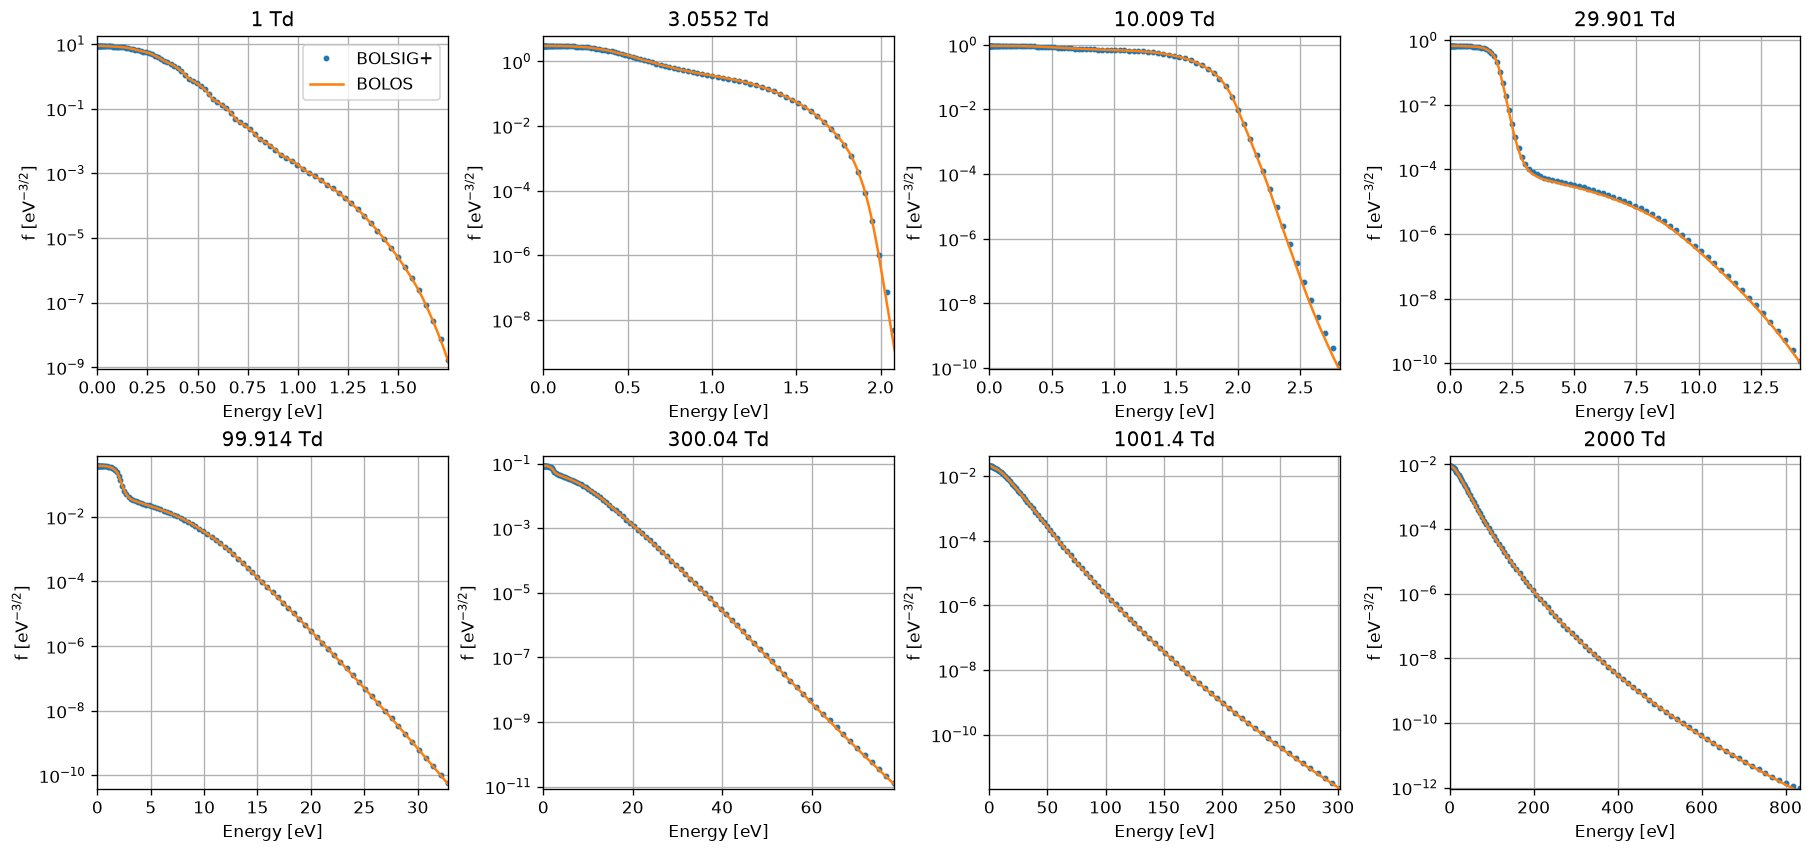

,E/N_Td,weighted_L1_percent,reference_sampled_population,max_core_relative_percent,common_min_eV,common_max_eV
0,1.00000,0.164771,0.999780,2.568051,0.000199,1.748702
1,3.05519,0.248509,0.999910,13.201701,0.000215,2.079707
2,10.00950,0.132431,0.999674,24.218184,0.000257,2.819554
3,29.90110,0.202336,0.998692,12.856910,0.000941,14.092970
4,99.91400,0.534523,0.999585,1.816408,0.001900,32.846090
5,300.03800,0.103861,0.999904,3.051436,0.004585,78.433420
6,1001.37000,0.080832,0.999843,2.725398,0.017736,301.820600
7,2000.00000,0.140645,0.999830,1.500301,0.044034,835.338500


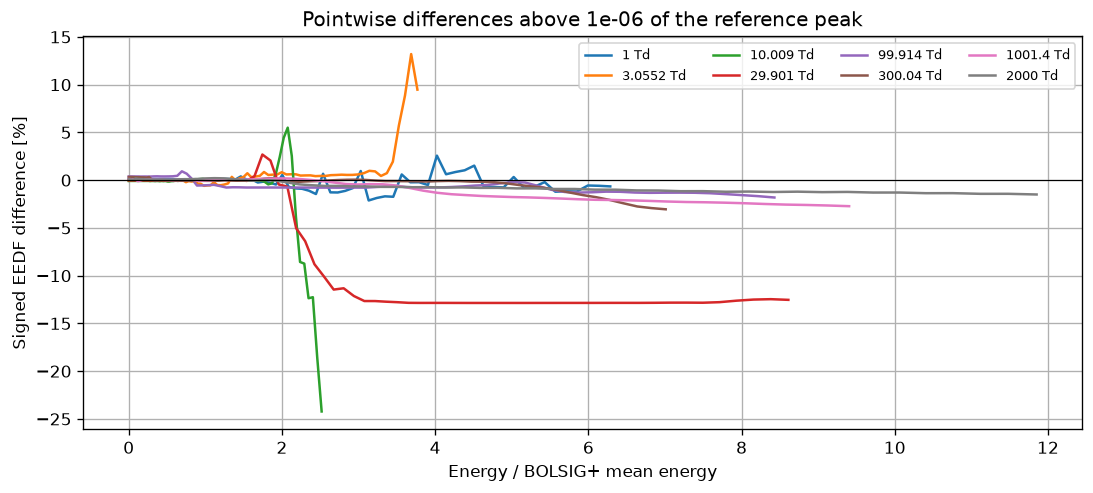

In [4]:
eedf_rows = []
eedf_samples = []
fig, axes = plt.subplots(2, 4, figsize=(15, 7), constrained_layout=True)
for ax, result in zip(axes.flat, results):
    ref = result["reference"]
    energy, reference_f = ref["eedf"][:, :2].T
    g, f = result["grid"], result["f"]
    mask = (energy >= g.x0) & (energy <= g.x1)
    x, fr = energy[mask], reference_f[mask]
    fb = np.interp(x, g.c, f, left=f[0], right=f[-1])
    core = fr > CORE_FRACTION * np.max(fr)
    reference_population = trapezoid(fr * np.sqrt(x), x)
    discrepancy = trapezoid(np.abs(fb - fr) * np.sqrt(x), x) / reference_population
    eedf_rows.append({"E/N_Td": ref["field"], "weighted_L1_percent": 100 * discrepancy,
                      "reference_sampled_population": reference_population,
                      "max_core_relative_percent": 100 * np.max(np.abs((fb[core] - fr[core]) / fr[core])),
                      "common_min_eV": x[0], "common_max_eV": x[-1]})
    eedf_samples.extend({"E/N_Td": ref["field"], "energy_eV": xx,
                         "BOLSIG_f": rr, "BOLOS_interpolated_f": bb}
                        for xx, rr, bb in zip(x, fr, fb))
    ax.semilogy(energy[reference_f > 0], reference_f[reference_f > 0], "o", ms=2.5, label="BOLSIG+")
    ax.semilogy(g.c[f > 0], f[f > 0], lw=1.5, label="BOLOS")
    ax.set(xlim=(0, energy[-1]), ylim=(max(reference_f.max() * 1e-10, 1e-30), reference_f.max() * 2),
           title=f"{ref['field']:.5g} Td", xlabel="Energy [eV]", ylabel="f [eV$^{-3/2}$]")
axes.flat[0].legend()
fig.savefig(OUT / "eedf_comparison.png", dpi=160)
plt.show()
eedf_table = pd.DataFrame(eedf_rows)
display(eedf_table)

fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
for result in results:
    x, fr = result["reference"]["eedf"][:, :2].T
    fb = np.interp(x, result["grid"].c, result["f"])
    core = fr > CORE_FRACTION * max(fr)
    ax.plot(x[core] / result["reference"]["mean_energy_eV"],
            100 * (fb[core] / fr[core] - 1), label=f"{result['reference']['field']:.5g} Td")
ax.axhline(0, color="k", lw=.7)
ax.set(xlabel="Energy / BOLSIG+ mean energy", ylabel="Signed EEDF difference [%]",
       title=f"Pointwise differences above {CORE_FRACTION:g} of the reference peak")
ax.legend(ncol=4, fontsize=8)
fig.savefig(OUT / "eedf_core_difference.png", dpi=160)
plt.show()

## 4. Representative reaction rate coefficients

The selected IDs cover rotational/vibrational excitation, electronic excitation,
ionization, and attachment in both species. The table below identifies the
exact input process and product, rather than relying on a potentially ambiguous
reaction name. Rates are **unweighted** (no molar-fraction multiplier).

Signed difference = `100 * (BOLOS - BOLSIG+) / BOLSIG+`. Reference rates at or
below `RATE_RELATIVE_FLOOR` have no percentage reported (`NaN`); absolute
differences remain available, and exported zeros are not treated as exact
physical zero rates. All 43 rates are retained in the exported long table.

,collision_ID,species,kind,product,threshold_eV,BOLSIG_label
0,C2,N2,EXCITATION,N2(rot),0.020,N2 Excitation 0.020 eV
1,C4,N2,EXCITATION,N2(v1res),0.291,N2 Excitation 0.29 eV
2,C21,N2,EXCITATION,N2(C3),11.030,N2 Excitation 11.03 eV
3,C25,N2,IONIZATION,N2^+,15.600,N2 Ionization 15.60 eV
4,C28,O2,ATTACHMENT,O^-+O,0.000,O2 Attachment
5,C31,O2,EXCITATION,O2(v1),0.190,O2 Excitation 0.19 eV
6,C37,O2,EXCITATION,O2(a1),0.977,O2 Excitation 0.98 eV
7,C43,O2,IONIZATION,O2^+,12.060,O2 Ionization 12.06 eV


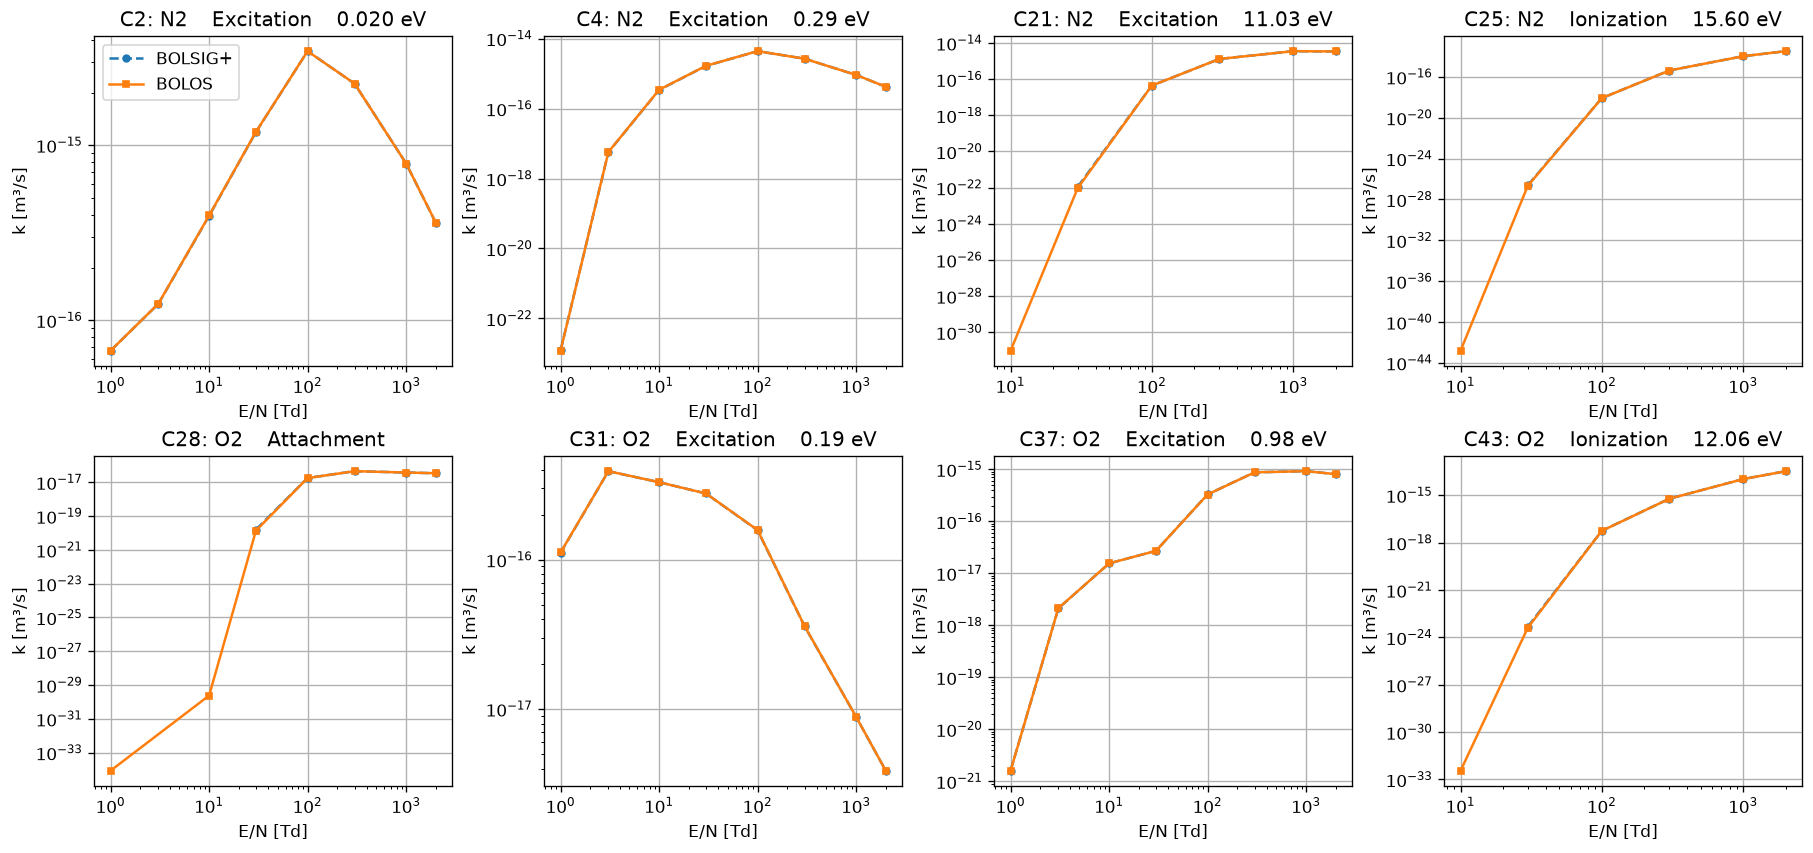

collision_ID,C2,C21,C25,C28,C31,C37,C4,C43
E/N_Td,,,,,,,,
1.00000,-0.046401,NaN,NaN,NaN,0.417347,-0.502354,-1.947965,NaN
3.05519,0.151218,NaN,NaN,NaN,0.093042,0.476529,0.960802,NaN
10.00950,0.489621,NaN,NaN,NaN,0.002634,0.088773,0.985973,NaN
29.90110,0.290220,-13.388352,NaN,-12.875846,0.000444,-0.104968,0.655966,-13.761957
99.91400,-0.047389,-0.690175,-1.432569,-0.796704,0.369979,-0.654010,0.020858,-0.954605
300.03800,0.041991,-0.050542,-0.119631,-0.079563,0.300409,-0.053986,0.056340,-0.109625
1001.37000,-0.038004,0.000568,-0.162859,-0.001410,0.075866,0.005321,-0.027527,-0.178241
2000.00000,0.142543,0.046413,-0.180887,-0.022378,0.071513,0.005043,0.136870,-0.201364


In [5]:
SELECTED_IDS = [2, 4, 21, 25, 28, 31, 37, 43]
mapping = pd.DataFrame([{
    "collision_ID": f"C{i}", "species": definitions[i-1]["target"],
    "kind": definitions[i-1]["kind"], "product": definitions[i-1].get("product", ""),
    "threshold_eV": definitions[i-1].get("threshold", 0),
    "BOLSIG_label": selected[0]["rates"][i]["label"],
} for i in SELECTED_IDS])
display(mapping)

rate_rows = []
for result in results:
    ref = result["reference"]
    for i, rate in enumerate(result["rates"], 1):
        reference_rate = ref["rates"][i]["rate"]
        rate_rows.append({"E/N_Td": ref["field"], "collision_ID": f"C{i}",
                          "BOLOS_m3_s": rate, "BOLSIG_m3_s": reference_rate,
                          "absolute_difference_m3_s": rate - reference_rate,
                          "signed_difference_percent": 100 * (rate/reference_rate - 1)
                          if reference_rate > RATE_RELATIVE_FLOOR else np.nan})
rates_table = pd.DataFrame(rate_rows)
fig, axes = plt.subplots(2, 4, figsize=(15, 7), constrained_layout=True)
for ax, i in zip(axes.flat, SELECTED_IDS):
    rows = rates_table[rates_table.collision_ID == f"C{i}"]
    for column, label, style in [("BOLSIG_m3_s", "BOLSIG+", "o--"), ("BOLOS_m3_s", "BOLOS", "s-")]:
        positive = rows[column] > 0
        ax.loglog(rows.loc[positive, "E/N_Td"], rows.loc[positive, column], style, ms=4, label=label)
    ax.set(title=f"C{i}: {selected[0]['rates'][i]['label']}", xlabel="E/N [Td]", ylabel="k [m³/s]")
axes.flat[0].legend()
fig.savefig(OUT / "reaction_rates.png", dpi=160)
plt.show()
display(rates_table[rates_table.collision_ID.isin([f"C{i}" for i in SELECTED_IDS])]
        .pivot(index="E/N_Td", columns="collision_ID", values="signed_difference_percent"))

## 5. Electron transport and energy

The directly comparable outputs are mean energy, reduced mobility, and reduced
diffusion. The characteristic energy is derived from their ratio in both
solvers and is not an additional independent transport calculation. BOLSIG+'s
energy mobility, energy diffusion, and anisotropy are not computed by this
BOLOS API and are deliberately not relabeled as comparable outputs.

,E/N_Td,quantity,BOLOS,BOLSIG,signed_difference_percent
0,1.00000,mean_energy_eV,2.272460e-01,2.274720e-01,-0.099358
1,1.00000,mobility_N,6.325860e+24,6.326330e+24,-0.007434
2,1.00000,diffusion_N,1.287633e+24,1.287960e+24,-0.025410
3,1.00000,characteristic_energy_eV,2.035506e-01,2.035872e-01,-0.017977
4,3.05519,mean_energy_eV,5.181458e-01,5.175200e-01,0.120919
5,3.05519,mobility_N,3.783619e+24,3.776700e+24,0.183206
6,3.05519,diffusion_N,1.569417e+24,1.565790e+24,0.231647
7,3.05519,characteristic_energy_eV,4.147926e-01,4.145921e-01,0.048352
8,10.00950,mean_energy_eV,9.388193e-01,9.385970e-01,0.023684
9,10.00950,mobility_N,2.039928e+24,2.029890e+24,0.494518


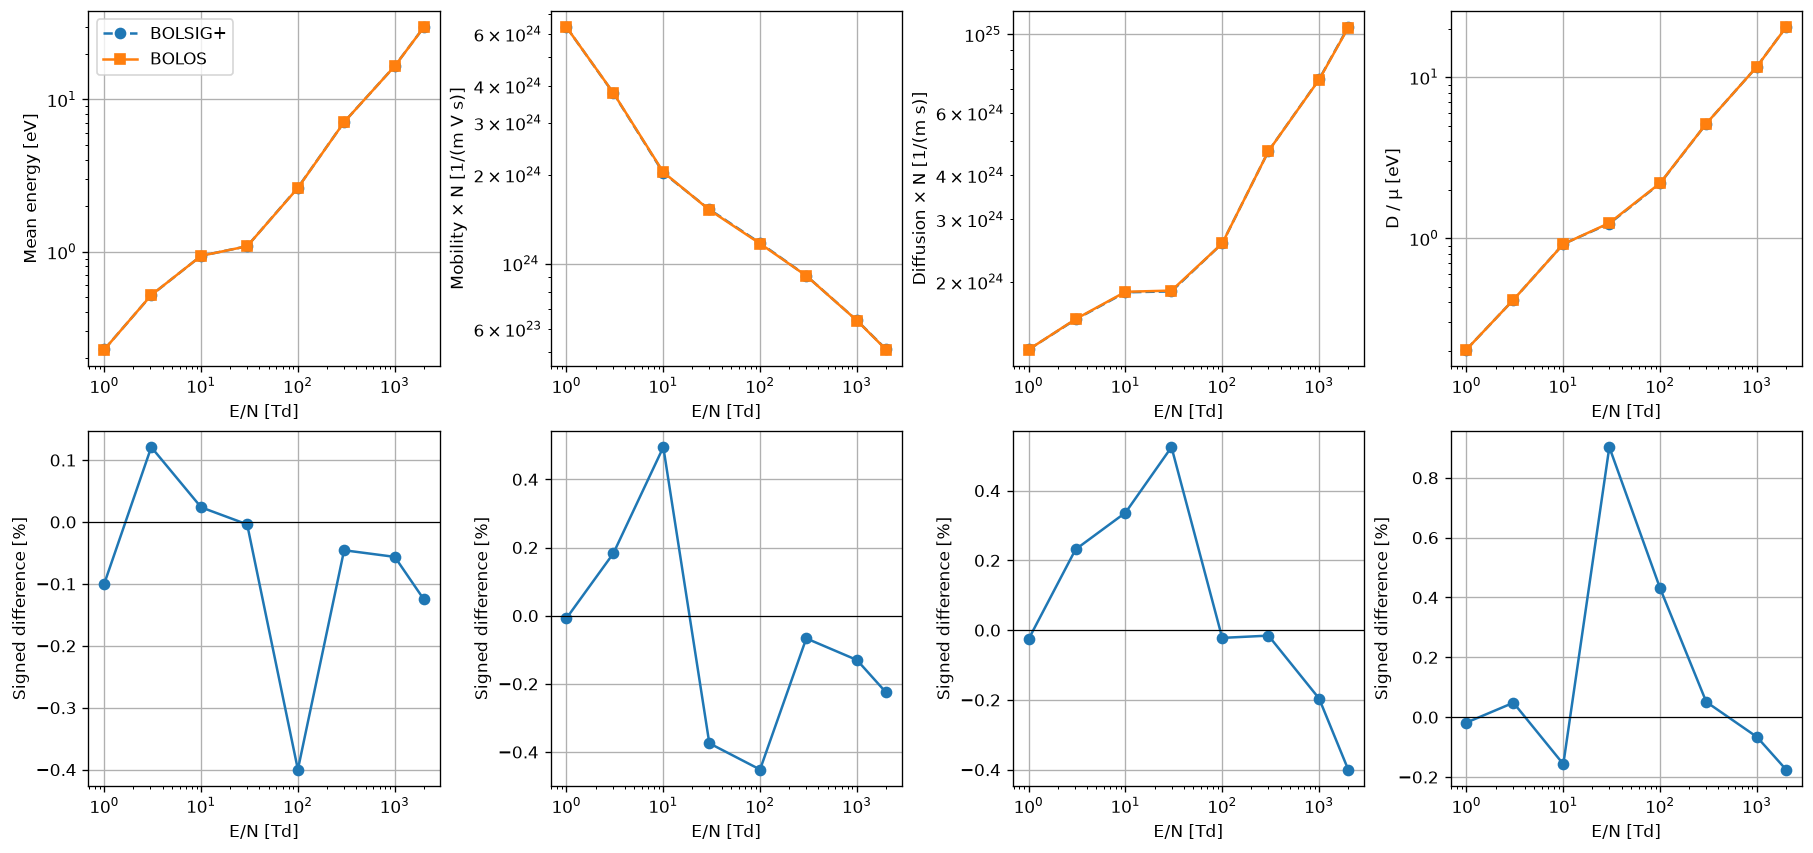

In [6]:
METRICS = {
    "mean_energy_eV": "Mean energy [eV]", "mobility_N": "Mobility × N [1/(m V s)]",
    "diffusion_N": "Diffusion × N [1/(m s)]", "characteristic_energy_eV": "D / μ [eV]",
}
transport_rows = []
for result in results:
    ref = result["reference"]
    for key in METRICS:
        reference_value = (ref["diffusion_N"] / ref["mobility_N"]
                           if key == "characteristic_energy_eV" else ref[key])
        value = result["metrics"][key]
        transport_rows.append({"E/N_Td": ref["field"], "quantity": key,
                               "BOLOS": value, "BOLSIG": reference_value,
                               "signed_difference_percent": 100 * (value/reference_value - 1)})
transport_table = pd.DataFrame(transport_rows)
display(transport_table)
fig, axes = plt.subplots(2, 4, figsize=(15, 7), constrained_layout=True)
for column, (key, label) in enumerate(METRICS.items()):
    rows = transport_table[transport_table.quantity == key]
    axes[0, column].loglog(rows["E/N_Td"], rows.BOLSIG, "o--", label="BOLSIG+")
    axes[0, column].loglog(rows["E/N_Td"], rows.BOLOS, "s-", label="BOLOS")
    axes[0, column].set(ylabel=label, xlabel="E/N [Td]")
    axes[1, column].semilogx(rows["E/N_Td"], rows.signed_difference_percent, "o-")
    axes[1, column].axhline(0, color="k", lw=.7)
    axes[1, column].set(xlabel="E/N [Td]", ylabel="Signed difference [%]")
axes[0, 0].legend()
fig.savefig(OUT / "transport_comparison.png", dpi=160)
plt.show()

## 6. Resolution/cutoff sensitivity, diagnostics, and interpretation

The following percentages compare BOLOS refinements with the primary BOLOS
solution, not with BOLSIG+. They help distinguish mesh dependence from a solver
difference; two refinements do not prove convergence. The cutoff extension also
changes the quadratic mesh, so its effect is not mathematically isolated from
all resolution changes. Inspect solver diagnostics and the high-energy tail,
especially for threshold-sensitive ionization rates.

No arbitrary pass/fail tolerance is imposed on agreement between independent
solvers. The notebook does assert successful BOLOS iteration, finite quantities,
and normalization; differences with BOLSIG+ are reported quantitatively.

In [7]:
sensitivity_rows = []
for result in results:
    for refinement, check in result["sensitivity"].items():
        for key in METRICS:
            sensitivity_rows.append({"E/N_Td": result["reference"]["field"],
                                     "refinement": refinement, "quantity": key,
                                     "change_percent": 100 * (check["metrics"][key] / result["metrics"][key] - 1)})
        for i in SELECTED_IDS:
            base = result["rates"][i-1]
            sensitivity_rows.append({"E/N_Td": result["reference"]["field"],
                                     "refinement": refinement, "quantity": f"C{i}",
                                     "change_percent": 100 * (check["rates"][i-1] / base - 1)
                                     if base > RATE_RELATIVE_FLOOR else np.nan})
sensitivity_table = pd.DataFrame(sensitivity_rows)
display(sensitivity_table.pivot_table(index=["E/N_Td", "refinement"],
                                    columns="quantity", values="change_percent"))

summary = {
    "max_abs_transport_difference_percent": float(transport_table.signed_difference_percent.abs().max()),
    "max_weighted_eedf_L1_percent": float(eedf_table.weighted_L1_percent.max()),
    "max_reported_selected_rate_difference_percent": float(
        rates_table[rates_table.collision_ID.isin([f"C{i}" for i in SELECTED_IDS])]
        .signed_difference_percent.abs().max()),
    "max_abs_BOLOS_refinement_change_percent": float(sensitivity_table.change_percent.abs().max()),
    "max_negative_population_fraction": float(diagnostics.negative_population_fraction.max()),
}
display(pd.Series(summary, name="Observed discrepancies (not acceptance limits)").to_frame())
display(Markdown(
    f"**Observed comparison:** the maximum transport/energy difference "
    f"(including the derived D/μ ratio) is "
    f"{summary['max_abs_transport_difference_percent']:.3f}%. "
    f"The largest population-weighted EEDF L1 discrepancy on the reference "
    f"samples is {summary['max_weighted_eedf_L1_percent']:.3f}%. "
    f"Selected reaction-rate differences reach "
    f"{summary['max_reported_selected_rate_difference_percent']:.3f}% "
    f"above the rate floor. Agreement is therefore quantity-dependent; "
    f"small bulk differences do not establish accuracy of every tail-sensitive rate."
))

diagnostic_text = "\n\n".join(
    f"{r['reference']['field']:.6g} Td\n{r['logs']}\nNumPy warnings: {r['runtime_warnings']}"
    for r in results
)
print(diagnostic_text)

quantity                     C2       C21       C25       C28       C31  \
E/N_Td     refinement                                                     
1.00000    cutoff     -0.003367       NaN       NaN       NaN  0.005904   
           resolution -0.007118       NaN       NaN       NaN  0.014203   
3.05519    cutoff     -0.002952       NaN       NaN       NaN  0.007470   
           resolution -0.010117       NaN       NaN       NaN  0.016822   
10.00950   cutoff     -0.007048       NaN       NaN       NaN  0.003271   
           resolution -0.008193       NaN       NaN       NaN  0.003719   
29.90110   cutoff     -0.002340 -0.181352       NaN -0.168014 -0.000237   
           resolution -0.005024 -0.398257       NaN -0.367706  0.000222   
99.91400   cutoff      0.000742  0.008594  0.001118  0.009184 -0.005473   
           resolution  0.004010  0.001058 -0.015864  0.001200 -0.001642   
300.03800  cutoff      0.002694  0.002000  0.000763  0.001030 -0.013192   
           resolution  0.004708  0.003055  0.000640  0.000915 -0.015950   
1001.37000 cutoff     -0.000301  0.000305  0.000150 -0.000151 -0.004166   
           resolution -0.001326  0.000455  0.000511 -0.000733 -0.002456   
2000.00000 cutoff     -0.000798 -0.000253 -0.000036 -0.000286  0.000155   
           resolution -0.001972 -0.000597 -0.000158 -0.000372 -0.003997   

quantity                    C37        C4       C43  characteristic_energy_eV  \
E/N_Td     refinement                                                           
1.00000    cutoff     -0.251995 -0.316979       NaN                 -0.009475   
           resolution -0.504223 -0.669737       NaN                 -0.007623   
3.05519    cutoff     -0.008842 -0.007547       NaN                 -0.053762   
           resolution -0.028904 -0.020621       NaN                 -0.047618   
10.00950   cutoff     -0.008892 -0.006797       NaN                  0.012455   
           resolution -0.012481 -0.001578       NaN                 -0.004355   
29.90110   cutoff     -0.004257 -0.001074 -0.187733                 -0.019525   
           resolution -0.012287 -0.003625 -0.414495                 -0.024243   
99.91400   cutoff      0.008269  0.000070  0.006934                  0.000751   
           resolution  0.002276  0.001783 -0.002607                 -0.022668   
300.03800  cutoff      0.001102  0.003045  0.001259                 -0.013875   
           resolution  0.001362  0.003946  0.001620                 -0.011676   
1001.37000 cutoff     -0.000047 -0.000859  0.000117                 -0.002585   
           resolution -0.000435 -0.001926  0.000418                 -0.001775   
2000.00000 cutoff     -0.000324 -0.000795 -0.000078                 -0.001514   
           resolution -0.000584 -0.002223 -0.000271                 -0.002320   

quantity               diffusion_N  mean_energy_eV  mobility_N  
E/N_Td     refinement                                           
1.00000    cutoff        -0.000600       -0.005992    0.008876  
           resolution    -0.000949       -0.012385    0.006674  
3.05519    cutoff        -0.010228       -0.002705    0.043557  
           resolution    -0.008651       -0.009710    0.038986  
10.00950   cutoff         0.007164       -0.001911   -0.005291  
           resolution    -0.002873       -0.000620    0.001482  
29.90110   cutoff        -0.019170        0.000256    0.000355  
           resolution    -0.023384       -0.000427    0.000859  
99.91400   cutoff         0.007244        0.004909    0.006493  
           resolution    -0.016326        0.000957    0.006343  
300.03800  cutoff        -0.012157        0.001044    0.001719  
           resolution    -0.009371        0.001295    0.002306  
1001.37000 cutoff        -0.002116       -0.000066    0.000469  
           resolution    -0.000702       -0.000176    0.001072  
2000.00000 cutoff        -0.001089       -0.000543    0.000424  
           resolution    -0.001425       -0.001297    0.000894

,Observed discrepancies (not acceptance limits)
max_abs_transport_difference_percent,9.024657e-01
max_weighted_eedf_L1_percent,5.345231e-01
max_reported_selected_rate_difference_percent,1.376196e+01
max_abs_BOLOS_refinement_change_percent,6.697371e-01
max_negative_population_fraction,5.723869e-15


**Observed comparison:** the maximum transport/energy difference (including the derived D/μ ratio) is 0.902%. The largest population-weighted EEDF L1 discrepancy on the reference samples is 0.535%. Selected reaction-rate differences reach 13.762% above the rate floor. Agreement is therefore quantity-dependent; small bulk differences do not establish accuracy of every tail-sensitive rate.

1 Td
Target N2: EFFECTIVE minus INELASTIC is negative at 6 table nodes (1500..10000 eV); clipped to zero. Interpolated ELASTIC may be affected within 1000..10000 eV. This can reflect constant extrapolation beyond individual tables, not necessarily invalid source data.
EEDF tail slopes undefined in 10 occupied cells (energy 13.7..20.5 eV; discrete population fraction 1.69e-16). Legacy zero-integral fallback retained; check grid/cutoff convergence before ignoring.
EEDF tail slopes undefined in 2 occupied cells (energy 2.88638..2.94103 eV; discrete population fraction 2.14e-17). Legacy zero-integral fallback retained; check grid/cutoff convergence before ignoring.
EEDF tail slopes undefined in 12 occupied cells (energy 1.99877..4.96498 eV; discrete population fraction 3.75e-19). Legacy zero-integral fallback retained; check grid/cutoff convergence before ignoring.
EEDF tail slopes undefined in 13 occupied cells (energy 2.00671..5.76089 eV; discrete population fraction 1.27e-18). Legacy ze

## 7. Save auditable results

CSV files, figures, and a provenance/diagnostics JSON are saved under
`validation/bolsig_comparison_corrected/`. The notebook itself retains tables and figures.
Rerunning replaces those generated comparison artifacts. Source files and input
data are not modified. The EEDF CSV contains the reference samples and BOLOS
values interpolated onto them; it is not a new BOLSIG+ calculation.

In [8]:
# tables = {"transport": transport_table, "rates_all_43": rates_table,
#           "eedf_metrics": eedf_table, "eedf_common_samples": pd.DataFrame(eedf_samples),
#           "solver_diagnostics": diagnostics, "grid_sensitivity": sensitivity_table,
#           "selected_process_mapping": mapping}
# for name, table in tables.items():
#     table.to_csv(OUT / f"{name}.csv", index=False)

# metadata = {"environment": environment, "reference_version": reference_header,
#             "requested_fields_Td": REQUESTED_FIELDS,
#             "actual_fields_Td": [r["field"] for r in selected],
#             "configuration": {"primary_cells": FINAL_CELLS, "refined_cells": REFINED_CELLS,
#                               "rtol": RTOL, "core_fraction": CORE_FRACTION,
#                               "rate_relative_floor_m3_s": RATE_RELATIVE_FLOOR},
#             "summary": summary,
#             "solver_logs_and_runtime_warnings": diagnostic_text,
#             "reference_settings": [{k: v for k, v in ref.items() if k not in {"rates", "eedf"}}
#                                    for ref in selected]}
# (OUT / "comparison_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
# print("Saved artifacts:")
# for path in sorted(OUT.iterdir()):
#     print(path.relative_to(ROOT).as_posix())